# Question 5: SNAP enrollment and food shelf use

The ask: SNAP gives a household money to buy food. A food shelf gives a household food directly. Do the two move together, or does one replace the other? The SNAP benefits may change from time-to-time, what happens to food shelf activity when the SNAP benefits change? Does the relationship between SNAP benefits and food shelf activity differ across locations? Understanding the nature of this relationship helps The Food Group highlight the importance of SNAP to lawmakers and in turn helps them make better informed decisions.

**Required:** a public SNAP source joined to the food-shelf data, with **source, grain, and publication lag** stated (see Datasets below).

### How this notebook answers each part
| Sub-question | What we measure | Section |
|---|---|---|
| **Q5-A. Move together or substitute?** | Within-county co-movement of food-shelf activity with (i) SNAP **enrollment** and (ii) SNAP **benefit per person**, net of statewide month shocks | Q5-A |
| **Q5-B. What happens when benefits change?** | Natural experiment: end of SNAP **Emergency Allotments** (Apr 2023 in accounting months). Counties that lost more $/person = higher "dose". Plus the 2026 enrollment drop if food-shelf data reaches 2026 | Q5-B |
| **Q5-C. Does it differ across locations?** | Metro (7-county Twin Cities) vs Greater Minnesota; county-by-county response to the EA cut | Q5-C |

**Outcome metrics (reported separately, per the brief):** visits (`HouseholdsReg`), pounds distributed (`PoundsReg`), individuals served (`IndividualsReg`).

Datasets:
| File | Grain | Role |
|---|---|---|
| `org_FSStats.xlsx` | Site × month | Monthly food-shelf visits (households), pounds distributed, individuals served |
| `Organization.xlsx` | Organization | Partner master file: type, status, location (`block_geoid` → county) |
| `Q5-snap-dashboard-data.xlsx` | County/Tribe × month (88 units, Jan 2016 – Aug 2026) | Monthly SNAP cases, persons, and net benefits issued (federal SNAP + state MFIP/MFAP food portions); joined to food-shelf data on county × month |
| `Q5-snap-dashboard-statewide-totals.xlsx` | Statewide × month (Jan 2016 – Aug 2026) | Statewide SNAP totals for trend charts and to check the county sums |

**SNAP source — grain & publication lag**
* **Grain:** county or Tribal Nation × month. Report month is the **accounting month** (when benefits were paid), net of cancelled payments.
* **Publication lag:** published monthly; data through **Aug 2026** was available when accessed on **2026-09-28** → about **1 month**.
* **Why this source:** monthly and county-level (joins directly to food-shelf county × month), back to 2016, covers the Emergency Allotment end. Chosen over the DHS calendar-year reports, which are annual summaries of the same counts.

Sources:
- Minnesota Department of Children, Youth, and Families (DCYF). *SNAP Food Assistance Data Dashboard — county/Tribe monthly data* (`snap-dashboard-data-through-august-2026.xlsx`), monthly by county or Tribal Nation (accounting month), Jan 2016 – Aug 2026; household cases, persons, and food benefits issued, cancelled, and net by funding source (federal SNAP, state MFAP, MFIP food portion). https://dcyf.mn.gov/snap-food-assistance-minnesota (data through August 2026; accessed 2026-09-28)
- Minnesota Department of Children, Youth, and Families (DCYF). *SNAP Food Assistance Data Dashboard — statewide totals* (`snap-dashboard-statewide-totals-through-august-2026.xlsx`), monthly, statewide, Jan 2016 – Aug 2026; same measures as above. https://dcyf.mn.gov/snap-food-assistance-minnesota (data through August 2026; accessed 2026-09-28)

## Setup

In [1]:
# !pip install -q statsmodels openpyxl   # uncomment if needed in Colab
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Chart palette (fixed order; validated categorical slots)
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRID = "#e6e5e1"
plt.rcParams.update({
    "figure.figsize": (11, 4.5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 2,
    "axes.titleweight": "bold", "axes.titlesize": 12,
})

### Import Data

In [2]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = "/content/drive/MyDrive/MinneMUDAC 26 for BU/Suji/Data/Q5"

FS_PATH         = f"{DATA_DIR}/org_FSStats.xlsx"
ORG_PATH        = f"{DATA_DIR}/Organization.xlsx"
SNAP_PATH       = f"{DATA_DIR}/Q5-snap-dashboard-data.xlsx"
SNAP_STATE_PATH = f"{DATA_DIR}/Q5-snap-dashboard-statewide-totals.xlsx"

fs_raw   = pd.read_excel(FS_PATH)
org_raw  = pd.read_excel(ORG_PATH)
snap_raw = pd.read_excel(SNAP_PATH, parse_dates=["Report_Month"])
snap_st  = pd.read_excel(SNAP_STATE_PATH, parse_dates=["Report_Month"])

for name, df in [("org_FSStats", fs_raw), ("Organization", org_raw),
                 ("SNAP county", snap_raw), ("SNAP statewide", snap_st)]:
    print(f"{name:15s} {df.shape}")
    print("   ", list(df.columns)[:30], "\n")

Mounted at /content/drive
org_FSStats     (28287, 58)
    ['__ID', '_id_site', '_Year', '_Month', 'DateForSearch', 'zzCreationTS', 'zzModificationTS', 'AdultsReg', 'ChildrenReg', 'HouseholdsReg', 'IndividualsReg', 'Meals', 'Misc', 'People', 'PoundsReg', 'SeniorsReg', 'Snacks', 'UniqueVisitsReg', 'County', 'FederalDistrict', 'StateDistrict', 'FoodBank', 'ChildrenExtra', 'ChildrenProduce', 'ChildrenHoliday', 'AdultsExtra', 'AdultsProduce', 'AdultsHoliday', 'IndividualsExtra', 'SeniorsExtra'] 

Organization    (1202, 68)
    ['__ID', 'CreateTime', 'zzCreationTS', 'zzModificationTS', '_id_type', 'City', 'State', 'Zip', 'MailCity', 'MailState', 'MailZip', 'Eligibility', 'Conditions', 'MarketSeasons', 'zcountDaysOperations', 'Region', 'SuperRegion', 'County', 'StateDistrict', 'FederalDistrict', 'DistrictSection', 'AgencyType', '_id_subtype', 'AgencySubType', 'isFoodBank', 'isAgency', 'isDistributionSite', 'HoldsInventoryForOthers', 'isWebscmShipTo', 'WebscmShipToName'] 

SNAP county     (112

### Analysis Settings

In [3]:
# --- Food-shelf columns (confirmed in the Data Dictionary) ---
METRICS = {"HouseholdsReg": "visits", "PoundsReg": "pounds", "IndividualsReg": "individuals"}

# --- Join key (verified: org_FSStats._id_site matches Organization.__ID for 99.9% of rows) ---
FS_KEY     = "_id_site"   # site ID in org_FSStats (NOT __ID, which is the stats-row ID)
ORG_ID_COL = "__ID"       # organization ID in Organization

# --- Food-shelf filter (decide after looking at the AgencyType value counts below) ---
AGENCYTYPE_COL = "AgencyType_org"   # Organization master record; or "AgencyType_fs"
EXCLUDE_TYPES  = ["Farmers Market", "Food Bank", "Meal Program"]   # not household food-shelf distribution
KEEP_TYPES     = None               # set a list to keep ONLY these values instead

# HouseholdsReg > IndividualsReg is impossible by definition. Flag rows with ratio >= this.
HH_INDIV_ERROR_RATIO = 2.0
# What to do with flagged rows: "null_individuals" | "null_both" | "keep"
ERROR_POLICY = "null_individuals"

# Balanced panel: keep sites that report in at least this share of months
MIN_REPORT_SHARE = 0.9
# Drop trailing months where fewer than this share of the usual sites have reported yet (late reporting)
MIN_TRAILING_COVERAGE = 0.8

# Tribal SNAP units: "fold" into the main county, or "drop"
TRIBE_POLICY = "fold"

# Key policy date. The last EA issuance was for Feb 2023, but it was PAID in March,
# so in the dashboard's accounting months the first month without EA is April 2023 (verified in Q5-B).
EA_FIRST_POST = pd.Timestamp("2023-04-01")

### Join key check

In [4]:
def norm_key(s):
    # Compare IDs as clean strings so 123 and 123.0 match
    return s.astype("string").str.strip().str.replace(r"\.0$", "", regex=True)

fs_ids  = norm_key(fs_raw[FS_KEY])
org_ids = norm_key(org_raw[ORG_ID_COL])
print(f"{FS_KEY} → Organization.{ORG_ID_COL}: match rate {fs_ids.isin(set(org_ids.dropna())).mean():.1%}")
print(f"Organization.{ORG_ID_COL} unique: {org_ids.dropna().is_unique}")
# Diagnostic (2026-10-06): __ID↔__ID matched only by coincidence (stats-row ID), _id_bank / id_agency are
# the supplying food bank / parent agency, so _id_site is the correct site-level key.

_id_site → Organization.__ID: match rate 99.9%
Organization.__ID unique: True


## Clean the food shelf data

Rules from `Data Dictionary.xlsx`
1. Use only the live **Reg** fields; Extra/Produce/Holiday/Total fields are deprecated.
2. Keep **food shelves** only (the Organization table also holds food banks and agencies).
3. Do **not** drop inactive organizations from history. Only drop months after their `InactiveDate`.
4. Fix the `HouseholdsReg > IndividualsReg` data errors.
5. Recompute the ratio columns instead of trusting the stored ones.

### Attach org attributes & Filter to food shelves

In [5]:
fs  = fs_raw.copy()
org = org_raw.copy()
fs["_key"]  = norm_key(fs[FS_KEY])
org["_key"] = norm_key(org[ORG_ID_COL])

# Month from _Year/_Month (DateForSearch / zz*TS are system fields)
fs["month"] = pd.to_datetime(dict(year=pd.to_numeric(fs["_Year"], errors="coerce"),
                                  month=pd.to_numeric(fs["_Month"], errors="coerce"), day=1),
                             errors="coerce")
print(f"Unparseable months: {fs['month'].isna().sum():,}")
fs = fs.dropna(subset=["month"])

# Duplicate site-months: keep the most recently modified record
dup = fs.duplicated(["_key", "month"], keep=False)
print(f"Duplicate site-month rows: {dup.sum():,}")
if dup.any():
    fs = (fs.sort_values("zzModificationTS")
            .drop_duplicates(["_key", "month"], keep="last"))

org_keep = ["_key", "AgencyType", "AgencySubType", "isActive", "ActiveInactive",
            "InactiveDate", "block_geoid", "County"]
org = org[[c for c in org_keep if c in org.columns]].drop_duplicates("_key")

# AgencyType and County exist in both tables: keep both with suffixes
fs = fs.merge(org, on="_key", how="left", suffixes=("_fs", "_org"),
              validate="many_to_one", indicator=True)
print(f"Join match rate: {(fs['_merge'] == 'both').mean():.1%}")
fs = fs.drop(columns="_merge")
ORG_KEY = "_key"   # later cells group by this

# One county-name column for the geography fallback: master record first, stats record second
fs["County"] = fs["County_org"].fillna(fs["County_fs"])
county_name_cols = ["County"]

for col in ["AgencyType_fs", "AgencyType_org", "AgencySubType"]:
    if col in fs.columns:
        print(f"\n{col}:\n{fs[col].value_counts(dropna=False).to_string()}")

Unparseable months: 26
Duplicate site-month rows: 87
Join match rate: 99.9%

AgencyType_fs:
AgencyType_fs
Brick and Mortar Site      14692
Food Shelf                  7401
Outreach Program            2476
Meal Program                1593
On-Site Meal Programs       1039
Mobile                       354
Tribal Program               222
College Campus Program       165
NaN                          138
Meal Programs                 89
Other Non-Profit              22
Agency or Tribal Nation       17
Brick and Mortar Sites         9

AgencyType_org:
AgencyType_org
Brick and Mortar Site      21328
Outreach Program            3514
Meal Program                2699
Tribal Program               267
College Campus Program       265
NaN                          130
Agency or Tribal Nation       14

AgencySubType:
AgencySubType
NaN                    26046
Mobile                  2134
Pop-up Distribution       37


**Food-shelf filter.** `org_FSStats` only holds sites that report food-shelf distribution, but the Organization master also types some of them as farmers markets, meal programs, or the food bank itself. These are dropped because they are not household food-shelf visits. **Confirm `EXCLUDE_TYPES` / `KEEP_TYPES` in the settings against the value counts above** and record the decision on the methods slide.

In [6]:
types = fs[AGENCYTYPE_COL].fillna("(missing)")
keep = types.isin(KEEP_TYPES) if KEEP_TYPES else ~types.isin(EXCLUDE_TYPES)

print("Rows by type → kept?")
print(pd.DataFrame({"rows": types.value_counts(), "kept": types.groupby(types).apply(lambda s: keep[s.index].all())})
        .sort_values("rows", ascending=False).to_string())

fs = fs[keep].copy()
assert len(fs) > 0, "Filter removed every row: check EXCLUDE_TYPES / KEEP_TYPES against the value counts"
print(f"\nFood-shelf rows kept: {len(fs):,} | sites: {fs[ORG_KEY].nunique():,} | "
      f"months: {fs['month'].min():%Y-%m} → {fs['month'].max():%Y-%m}")

Rows by type → kept?
                          rows   kept
AgencyType_org                       
Brick and Mortar Site    21328   True
Outreach Program          3514   True
Meal Program              2699  False
Tribal Program             267   True
College Campus Program     265   True
(missing)                  130   True
Agency or Tribal Nation     14   True

Food-shelf rows kept: 25,518 | sites: 600 | months: 2022-01 → 2026-07


### Drop only the months after a site went inactive

In [7]:
if "InactiveDate" in fs.columns:
    inact = pd.to_datetime(fs["InactiveDate"], errors="coerce")
    after_close = inact.notna() & (fs["month"] > inact)
    print(f"Rows after InactiveDate dropped: {after_close.sum():,}")
    fs = fs[~after_close].copy()

Rows after InactiveDate dropped: 30


### Metric cleaning

* Coerce to numeric; a month where **both** visits and pounds are 0 is treated as *not reported*.
* `HouseholdsReg / IndividualsReg >= HH_INDIV_ERROR_RATIO` is flagged as a data error. Individuals are self-reported (Data Catalog), so the default nulls `IndividualsReg` only. Try `ERROR_POLICY="null_both"` as a sensitivity check.

In [8]:
for c in METRICS:
    fs[c] = pd.to_numeric(fs[c], errors="coerce")

not_reported = (fs["HouseholdsReg"].fillna(0) == 0) & (fs["PoundsReg"].fillna(0) == 0)
fs.loc[not_reported, list(METRICS)] = np.nan

ratio = fs["HouseholdsReg"] / fs["IndividualsReg"].replace(0, np.nan)
fs["flag_hh_gt_indiv"] = ratio >= HH_INDIV_ERROR_RATIO
print(f"Not-reported site-months: {not_reported.sum():,}")
print(f"Flagged HH>Indiv errors (ratio >= {HH_INDIV_ERROR_RATIO}): {fs['flag_hh_gt_indiv'].sum():,}")

if ERROR_POLICY == "null_individuals":
    fs.loc[fs["flag_hh_gt_indiv"], "IndividualsReg"] = np.nan
elif ERROR_POLICY == "null_both":
    fs.loc[fs["flag_hh_gt_indiv"], ["IndividualsReg", "HouseholdsReg"]] = np.nan

# Recompute ratios from cleaned values (do not use stored PoundsPerHH etc.)
fs["pounds_per_hh"] = fs["PoundsReg"] / fs["HouseholdsReg"]
fs["indiv_per_hh"]  = fs["IndividualsReg"] / fs["HouseholdsReg"]
fs[list(METRICS) + ["pounds_per_hh", "indiv_per_hh"]].describe().T

Not-reported site-months: 1,016
Flagged HH>Indiv errors (ratio >= 2.0): 22


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:53: RuntimeWarning: invalid value encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


,count,mean,std,min,25%,50%,75%,max
HouseholdsReg,24405.0,5.135334e+02,2180.126903,0.0,63.000000,153.000000,458.000000,273385.0
PoundsReg,24398.0,2.697342e+04,54484.192229,-4415.0,3280.000000,8261.000000,26105.750000,994394.0
IndividualsReg,24390.0,1.513769e+03,4075.857038,0.0,157.000000,422.000000,1279.000000,89669.0
pounds_per_hh,24331.0,NaN,NaN,-inf,38.562562,56.909091,79.064892,inf
indiv_per_hh,24374.0,inf,NaN,0.0,2.222222,2.733333,3.323302,inf


## Geography: map each site to a SNAP unit

`block_geoid` → first 5 digits = county FIPS → county name.

The SNAP dashboard is not a clean 87-county list, so we build a **`snap_unit`** that both sides share:

| SNAP dashboard entity | What it covers | Food-shelf counties mapped to it |
|---|---|---|
| `MNPrairie` | Dodge + Steele + Waseca consortium | Dodge, Steele, Waseca |
| `Pope` (from Jan 2022) | Western Prairie Human Services = Pope + Grant (Grant series ends Dec 2021) | Pope, Grant |
| `Mille Lacs Band`, `Red Lake Nation`, `White Earth Band` | Tribal Nations administer their own SNAP | `TRIBE_POLICY="fold"` adds them to Mille Lacs, Beltrami, Mahnomen |

All other units are single counties.

In [9]:
# Minnesota counties in DHS county-code order (code n -> FIPS 27 + (2n-1)), spelled as in the SNAP dashboard
MN_COUNTIES = ["Aitkin","Anoka","Becker","Beltrami","Benton","Big Stone","Blue Earth","Brown","Carlton","Carver",
    "Cass","Chippewa","Chisago","Clay","Clearwater","Cook","Cottonwood","Crow Wing","Dakota","Dodge","Douglas",
    "Faribault","Fillmore","Freeborn","Goodhue","Grant","Hennepin","Houston","Hubbard","Isanti","Itasca","Jackson",
    "Kanabec","Kandiyohi","Kittson","Koochiching","Lac Qui Parle","Lake","Lake of Woods","Le Sueur","Lincoln","Lyon",
    "McLeod","Mahnomen","Marshall","Martin","Meeker","Mille Lacs","Morrison","Mower","Murray","Nicollet","Nobles",
    "Norman","Olmsted","Otter Tail","Pennington","Pine","Pipestone","Polk","Pope","Ramsey","Red Lake","Redwood",
    "Renville","Rice","Rock","Roseau","St. Louis","Scott","Sherburne","Sibley","Stearns","Steele","Stevens","Swift",
    "Todd","Traverse","Wabasha","Wadena","Waseca","Washington","Watonwan","Wilkin","Winona","Wright","Yellow Medicine"]
assert len(MN_COUNTIES) == 87
FIPS_TO_COUNTY = {f"27{2*i+1:03d}": name for i, name in enumerate(MN_COUNTIES)}

COUNTY_TO_UNIT = {c: c for c in MN_COUNTIES}
COUNTY_TO_UNIT.update({"Dodge": "MNPrairie", "Steele": "MNPrairie", "Waseca": "MNPrairie", "Grant": "Pope"})
TRIBE_TO_COUNTY = {"Mille Lacs Band": "Mille Lacs", "Red Lake Nation": "Beltrami", "White Earth Band": "Mahnomen"}

METRO7 = {"Anoka", "Carver", "Dakota", "Hennepin", "Ramsey", "Scott", "Washington"}

def norm_county(s):
    # Normalize free-text county names to the dashboard spelling
    s = str(s).strip().replace(" County", "").title()
    fixes = {"Lac Qui Parle": "Lac Qui Parle", "Lake Of The Woods": "Lake of Woods", "Lake Of Woods": "Lake of Woods",
             "Saint Louis": "St. Louis", "St Louis": "St. Louis", "St. Louis": "St. Louis", "Mcleod": "McLeod"}
    return fixes.get(s, s)

geoid = fs["block_geoid"].astype("string").str.replace(r"\.0$", "", regex=True).str.zfill(15) \
        if "block_geoid" in fs.columns else pd.Series(pd.NA, index=fs.index, dtype="string")
fs["county"] = geoid.str[:5].map(FIPS_TO_COUNTY)
if county_name_cols:   # fallback when block_geoid is blank
    fs["county"] = fs["county"].fillna(fs[county_name_cols[0]].map(norm_county))
fs["county"] = fs["county"].where(fs["county"].isin(MN_COUNTIES))
fs["snap_unit"] = fs["county"].map(COUNTY_TO_UNIT)

unmatched = fs.loc[fs["snap_unit"].isna(), ORG_KEY].nunique()
print(f"Sites without a Minnesota county: {unmatched} (excluded from the join)")
fs = fs[fs["snap_unit"].notna()].copy()
print(f"Sites kept: {fs[ORG_KEY].nunique():,} across {fs['snap_unit'].nunique()} SNAP units")

Sites without a Minnesota county: 45 (excluded from the join)
Sites kept: 555 across 83 SNAP units


## SNAP & Build the county x month panel

### SNAP variables

* `snap_persons` = `PersonCount` → **enrollment**
* `snap_benefits` = `Total_Net` (federal SNAP + state MFAP + MFIP food portion, net of cancellations). We use the total because `PersonCount` covers all three.
* `benefit_pp` = `snap_benefits / snap_persons` → **benefit generosity**. This is what dropped when Emergency Allotments ended.

In [12]:
snap = snap_raw.rename(columns={"Report_Month": "month", "CountyTribeName": "entity"}).copy()
snap["month"] = snap["month"].dt.to_period("M").dt.to_timestamp()

if TRIBE_POLICY == "fold":
    snap["snap_unit"] = snap["entity"].replace(TRIBE_TO_COUNTY)
else:
    snap = snap[~snap["entity"].isin(TRIBE_TO_COUNTY)]
    snap["snap_unit"] = snap["entity"]

snap = (snap.groupby(["snap_unit", "month"], as_index=False)
            .agg(snap_cases=("CaseCount", "sum"), snap_persons=("PersonCount", "sum"),
                 snap_benefits=("Total_Net", "sum"), snap_fed_net=("SNAP_Federal_Food_Net", "sum")))
snap["benefit_pp"] = snap["snap_benefits"] / snap["snap_persons"]

# Check: county sums vs statewide file
chk = snap.groupby("month")[["snap_persons", "snap_benefits"]].sum().join(
      snap_st.set_index(snap_st["Report_Month"].dt.to_period("M").dt.to_timestamp())[["PersonCount", "Total_Net"]])
print("Max abs % gap county-sum vs statewide (persons, benefits):",
      ((chk["snap_persons"] / chk["PersonCount"] - 1).abs().max() * 100),
      ((chk["snap_benefits"] / chk["Total_Net"] - 1).abs().max() * 100))

Max abs % gap county-sum vs statewide (persons, benefits): 0.0 0.0


### Aggregate food shelves to SNAP unit x month

Food-shelf totals can rise just because **new sites start reporting**. We therefore build two versions:
* `all`: every reporting site
* `balanced`: only sites reporting in ≥ `MIN_REPORT_SHARE` of months. This is the **default for inference**.

In [13]:
# Late reporting: the most recent months may not have all sites in yet. Trim them so they don't look like a drop.
sites_per_month = fs.dropna(subset=["HouseholdsReg"]).groupby("month")[ORG_KEY].nunique()
typical = sites_per_month.iloc[:-6].median()
tail_ok = (sites_per_month / typical >= MIN_TRAILING_COVERAGE)
last_good = tail_ok[tail_ok].index.max()
dropped_tail = sites_per_month[sites_per_month.index > last_good]
print(f"Typical reporting sites/month: {typical:.0f}. Trailing months dropped: {list(dropped_tail.index.strftime('%Y-%m'))}")
fs = fs[fs["month"] <= last_good].copy()

months_all = fs["month"].nunique()
share = fs.dropna(subset=["HouseholdsReg"]).groupby(ORG_KEY)["month"].nunique() / months_all
balanced_sites = share[share >= MIN_REPORT_SHARE].index
print(f"Balanced-panel sites: {len(balanced_sites):,} of {fs[ORG_KEY].nunique():,}")

def agg_fs(df):
    return (df.groupby(["snap_unit", "month"], as_index=False)
              .agg(visits=("HouseholdsReg", "sum"), pounds=("PoundsReg", "sum"),
                   individuals=("IndividualsReg", "sum"), n_sites=(ORG_KEY, "nunique")))

fs_all = agg_fs(fs.dropna(subset=["HouseholdsReg"]))
fs_bal = agg_fs(fs[fs[ORG_KEY].isin(balanced_sites)].dropna(subset=["HouseholdsReg"]))

Typical reporting sites/month: 443. Trailing months dropped: []
Balanced-panel sites: 361 of 555


### Join with SNAP

In [14]:
def build_panel(fs_agg):
    p = fs_agg.merge(snap, on=["snap_unit", "month"], how="inner", validate="one_to_one")
    p["metro"] = p["snap_unit"].isin(METRO7).astype(int)
    p["moy"] = p["month"].dt.month                      # month-of-year (seasonality)
    for c in ["visits", "pounds", "individuals", "snap_persons", "benefit_pp"]:
        p[f"ln_{c}"] = np.log(p[c].where(p[c] > 0))
    # Year-over-year log change (removes seasonality without needing pre-2022 food-shelf data)
    p = p.sort_values(["snap_unit", "month"])
    for c in ["visits", "pounds", "individuals", "snap_persons", "benefit_pp"]:
        lag12 = p.groupby("snap_unit")[f"ln_{c}"].shift(12)
        same_gap = p.groupby("snap_unit")["month"].shift(12) == p["month"] - pd.DateOffset(months=12)
        p[f"yoy_{c}"] = (p[f"ln_{c}"] - lag12).where(same_gap)
    return p

panel_all = build_panel(fs_all)
panel     = build_panel(fs_bal)      # default
print(f"Panel: {panel['snap_unit'].nunique()} units × {panel['month'].nunique()} months = {len(panel):,} rows")
print(f"Coverage: {panel['month'].min():%Y-%m} → {panel['month'].max():%Y-%m}")
panel.head()

Panel: 83 units × 55 months = 4,559 rows
Coverage: 2022-01 → 2026-07


,snap_unit,month,visits,pounds,individuals,n_sites,snap_cases,snap_persons,snap_benefits,snap_fed_net,benefit_pp,metro,moy,ln_visits,ln_pounds,ln_individuals,ln_snap_persons,ln_benefit_pp,yoy_visits,yoy_pounds,yoy_individuals,yoy_snap_persons,yoy_benefit_pp
0,Aitkin,2022-01-01,177.0,8831.0,400.0,4,685,1231,275717,259867,223.978067,0,1,5.176150,9.086024,5.991465,7.115582,5.411548,NaN,NaN,NaN,NaN,NaN
1,Aitkin,2022-02-01,177.0,8831.0,400.0,4,686,1230,286856,268919,233.216260,0,2,5.176150,9.086024,5.991465,7.114769,5.451966,NaN,NaN,NaN,NaN,NaN
2,Aitkin,2022-03-01,193.0,9803.0,423.0,4,688,1222,281177,265086,230.095745,0,3,5.262690,9.190444,6.047372,7.108244,5.438496,NaN,NaN,NaN,NaN,NaN
3,Aitkin,2022-04-01,240.0,10879.0,418.0,4,690,1213,279020,261859,230.024732,0,4,5.480639,9.294590,6.035481,7.100852,5.438187,NaN,NaN,NaN,NaN,NaN
4,Aitkin,2022-05-01,197.0,11423.0,460.0,4,700,1215,282679,264152,232.657613,0,5,5.283204,9.343384,6.131226,7.102499,5.449568,NaN,NaN,NaN,NaN,NaN


## Q5-A — Do SNAP and food shelves move together, or does one replace the other?
### Statewide picture (indexed, Jan 2022 = 100)
Uses the **balanced panel** so new sites joining do not look like rising demand. Both series are indexed to a common base, so one axis is enough. The shaded line marks the end of Emergency Allotments.

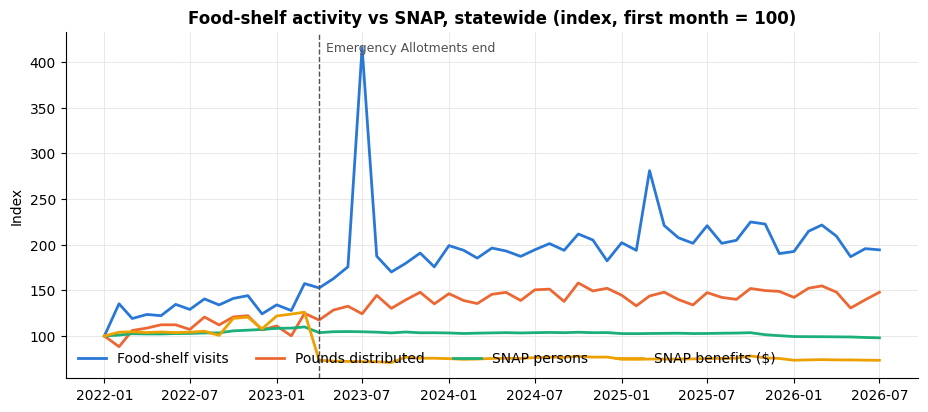

In [15]:
state = (panel.groupby("month")[["visits", "pounds", "individuals"]].sum()
         .join(snap.groupby("month")[["snap_persons", "snap_benefits"]].sum()))
base = state.iloc[0]
idx = state / base * 100

fig, ax = plt.subplots()
for col, color, label in [("visits", C1, "Food-shelf visits"), ("pounds", C2, "Pounds distributed"),
                          ("snap_persons", C3, "SNAP persons"), ("snap_benefits", C4, "SNAP benefits ($)")]:
    ax.plot(idx.index, idx[col], color=color, label=label)
ax.axvline(EA_FIRST_POST, color="#52514e", ls="--", lw=1)
ax.annotate("Emergency Allotments end", (EA_FIRST_POST, ax.get_ylim()[1]), xytext=(5, -14),
            textcoords="offset points", fontsize=9, color="#52514e")
ax.set_title("Food-shelf activity vs SNAP, statewide (index, first month = 100)")
ax.set_ylabel("Index"); ax.legend(frameon=False, ncol=4, loc="lower left")
plt.show()

### Lead/lag correlation of year-over-year changes (statewide)
Correlation of YoY % change in food-shelf visits with YoY change in SNAP benefit per person, `k` months earlier. A **negative** correlation is consistent with **substitution**: less SNAP money leads to more food-shelf use.

In [16]:
st = state.copy()
st["benefit_pp"] = st["snap_benefits"] / st["snap_persons"]
yoy = np.log(st).diff(12)
rows = []
for k in range(0, 7):
    rows.append({"lag_months": k,
                 "corr(visits, benefit_pp)":   yoy["visits"].corr(yoy["benefit_pp"].shift(k)),
                 "corr(visits, snap_persons)": yoy["visits"].corr(yoy["snap_persons"].shift(k)),
                 "corr(pounds, benefit_pp)":   yoy["pounds"].corr(yoy["benefit_pp"].shift(k))})
pd.DataFrame(rows).round(2)

,lag_months,"corr(visits, benefit_pp)","corr(visits, snap_persons)","corr(pounds, benefit_pp)"
0,0,-0.54,0.19,-0.56
1,1,-0.56,0.19,-0.63
2,2,-0.51,0.28,-0.64
3,3,-0.47,0.26,-0.61
4,4,-0.02,0.64,-0.61
5,5,0.01,0.64,-0.56
6,6,0.02,0.64,-0.56


### Panel regression (main Q5a result)
$$\ln Y_{ct} = \beta_1 \ln(\text{SNAP persons})_{ct} + \beta_2 \ln(\text{benefit per person})_{ct} + \alpha_c + \gamma_t + \varepsilon_{ct}$$

* $\alpha_c$ (unit fixed effects): compares each county **with itself**, so no population data is needed.
* $\gamma_t$ (month fixed effects): absorbs statewide shocks such as inflation, seasonality, and the statewide EA cut.
* Standard errors are clustered by SNAP unit.

**Interpretation:** $\beta_1 > 0$ means enrollment and food-shelf use **move together** (both track need). $\beta_2 < 0$ means more generous SNAP **replaces** food-shelf use. Both can hold at once.

In [17]:
def fe_reg(df, y, rhs="ln_snap_persons + ln_benefit_pp", extra=""):
    d = df.dropna(subset=[y, "ln_snap_persons", "ln_benefit_pp"])
    m = smf.ols(f"{y} ~ {rhs} {extra} + C(snap_unit) + C(month)", data=d).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(d["snap_unit"])[0]})
    return m

res = []
for y in ["ln_visits", "ln_pounds", "ln_individuals"]:
    m = fe_reg(panel, y)
    for v in ["ln_snap_persons", "ln_benefit_pp"]:
        res.append({"outcome": y, "term": v, "coef": m.params[v], "se": m.bse[v],
                    "p": m.pvalues[v], "n": int(m.nobs)})
q5a = pd.DataFrame(res).round(3)
q5a

,outcome,term,coef,se,p,n
0,ln_visits,ln_snap_persons,0.174,0.105,0.097,4559
1,ln_visits,ln_benefit_pp,0.385,0.191,0.044,4559
2,ln_pounds,ln_snap_persons,-0.044,0.139,0.750,4558
3,ln_pounds,ln_benefit_pp,0.291,0.209,0.163,4558
4,ln_individuals,ln_snap_persons,0.130,0.114,0.253,4558
5,ln_individuals,ln_benefit_pp,0.246,0.193,0.203,4558


## Q5-B — What happens to food shelves when SNAP benefits change?
### Natural experiment: end of Emergency Allotments (EA)
Every SNAP household got EA through the Feb 2023 issuance; then it stopped. Because the dashboard uses **accounting months**, the Feb 2023 EA payment shows up in **March**, so the drop appears in **April 2023** (printed below). The cut was statewide, but the **size of the cut per person differed by county**. That difference is our "dose":

$$\text{dose}_c = \overline{\text{benefit\_pp}}_{c,\,\text{Jan–Mar 2023}} - \overline{\text{benefit\_pp}}_{c,\,\text{Apr–Jun 2023}}$$

**Design (dose-response difference-in-differences on YoY changes):**
* **Pre:** Jan–Mar 2023 vs Jan–Mar 2022. Both years had EA, so this works as a placebo.
* **Post:** Apr–Sep 2023 vs Apr–Sep 2022. EA was present in 2022 and absent in 2023.
* Outcome = post YoY change − pre YoY change, regressed on dose (in $10 per person).

If the coefficient is **positive**, counties that lost more SNAP money saw food-shelf use rise more, which is evidence of **substitution**.

In [18]:
ppm = snap.set_index(["snap_unit", "month"])["benefit_pp"].unstack()
print("Statewide benefit per person around the EA end:")
print((snap.groupby("month")[["snap_benefits", "snap_persons"]].sum()
       .assign(benefit_pp=lambda d: d.snap_benefits / d.snap_persons)
       .loc["2022-11":"2023-06", "benefit_pp"].round(1)).to_string())

dose = (ppm.loc[:, "2023-01":"2023-03"].mean(axis=1) - ppm.loc[:, "2023-04":"2023-06"].mean(axis=1)).rename("dose")
print("\nEA cut per SNAP person ($/month) across units:")
print(dose.describe().round(1).to_string())
# Note: if the spread is small, the cross-county test has limited power. Say so on the slide.

Statewide benefit per person around the EA end:
month
2022-11-01    256.9
2022-12-01    227.9
2023-01-01    254.9
2023-02-01    258.6
2023-03-01    259.9
2023-04-01    160.3
2023-05-01    157.0
2023-06-01    155.8

EA cut per SNAP person ($/month) across units:
count     84.0
mean     110.5
std        9.3
min       84.6
25%      105.3
50%      112.9
75%      116.9
max      126.1


In [19]:
def window_mean(p, col, start, end):
    w = p[(p["month"] >= start) & (p["month"] <= end)]
    return w.groupby("snap_unit")[col].mean()

def ea_did(p, metric):
    pre  = np.log(window_mean(p, metric, "2023-01-01", "2023-03-01")) - np.log(window_mean(p, metric, "2022-01-01", "2022-03-01"))
    post = np.log(window_mean(p, metric, "2023-04-01", "2023-09-01")) - np.log(window_mean(p, metric, "2022-04-01", "2022-09-01"))
    out = pd.DataFrame({"pre_yoy": pre, "post_yoy": post}).join(dose)
    out["did"] = out["post_yoy"] - out["pre_yoy"]
    out["dose10"] = out["dose"] / 10
    out["metro"] = out.index.isin(METRO7).astype(int)
    return out.replace([np.inf, -np.inf], np.nan).dropna()

ea_rows, ea_data = [], {}
for metric in ["visits", "pounds", "individuals"]:
    d = ea_did(panel, metric)
    ea_data[metric] = d
    m = smf.ols("did ~ dose10", data=d).fit(cov_type="HC1")
    ea_rows.append({"metric": metric, "units": len(d),
                    "avg post-pre YoY change": d["did"].mean(),
                    "dose coef (per $10/person)": m.params["dose10"],
                    "se": m.bse["dose10"], "p": m.pvalues["dose10"]})
q5b = pd.DataFrame(ea_rows).round(3)
q5b

,metric,units,avg post-pre YoY change,dose coef (per $10/person),se,p
0,visits,83,0.143,-0.001,0.033,0.986
1,pounds,83,-0.052,0.001,0.022,0.973
2,individuals,83,0.013,0.043,0.028,0.131


### Event-study view: monthly YoY change in visits, by EA-dose group
YoY change by month during 2023, for counties with a high vs low per-person EA cut (split at the median). If the lines **separate from April 2023**, the cut shows up at the food shelf.

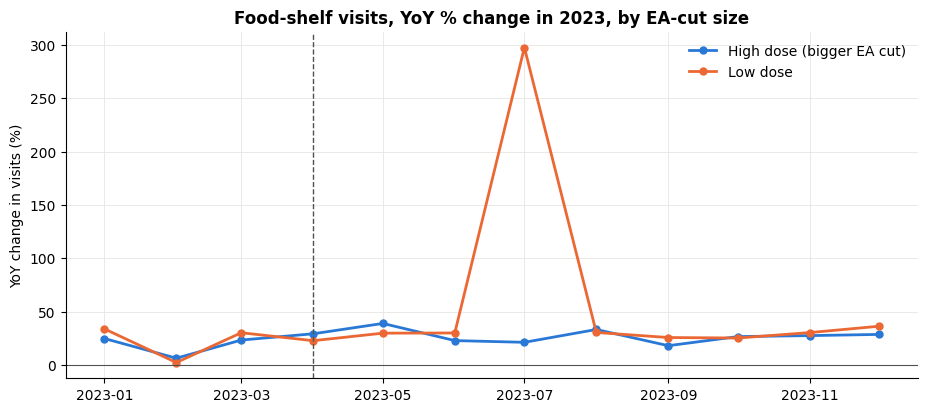

In [20]:
grp = (dose > dose.median()).map({True: "High dose (bigger EA cut)", False: "Low dose"})
es = panel.assign(group=panel["snap_unit"].map(grp)).dropna(subset=["yoy_visits", "group"])
es = es[(es["month"] >= "2023-01-01") & (es["month"] <= "2023-12-01")]
es_m = es.groupby(["month", "group"]).apply(
    lambda g: np.average(g["yoy_visits"], weights=g["visits"]), include_groups=False).unstack()

fig, ax = plt.subplots()
for col, color in zip(es_m.columns, [C1, C2]):
    ax.plot(es_m.index, es_m[col] * 100, marker="o", ms=5, color=color, label=col)
ax.axvline(EA_FIRST_POST, color="#52514e", ls="--", lw=1)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_title("Food-shelf visits, YoY % change in 2023, by EA-cut size")
ax.set_ylabel("YoY change in visits (%)"); ax.legend(frameon=False)
plt.show()

### Second benefit change: the 2026 SNAP enrollment drop (runs only if food-shelf data reaches 2026)
Statewide SNAP persons fell about 5% between late 2025 and mid-2026. Same YoY logic: did counties that lost more SNAP enrollees see bigger food-shelf increases?

In [21]:
if panel["month"].max() >= pd.Timestamp("2026-03-01"):
    last = panel["month"].max()
    w26 = panel[(panel["month"] >= "2026-01-01") & (panel["month"] <= last)]
    d26 = w26.groupby("snap_unit")[["yoy_visits", "yoy_pounds", "yoy_snap_persons"]].mean().dropna()
    d26["metro"] = d26.index.isin(METRO7).astype(int)
    for y in ["yoy_visits", "yoy_pounds"]:
        m = smf.ols(f"{y} ~ yoy_snap_persons", data=d26).fit(cov_type="HC1")
        print(f"{y:12s} on YoY SNAP persons: coef={m.params['yoy_snap_persons']:.3f} "
              f"(se {m.bse['yoy_snap_persons']:.3f}, p={m.pvalues['yoy_snap_persons']:.3f}), n={len(d26)}")
else:
    print(f"Food-shelf data ends {panel['month'].max():%Y-%m}; 2026 analysis skipped.")

yoy_visits   on YoY SNAP persons: coef=-0.296 (se 0.299, p=0.322), n=82
yoy_pounds   on YoY SNAP persons: coef=-0.104 (se 0.477, p=0.828), n=82


## Q5-C — Does the relationship differ across locations?
### Metro vs Greater Minnesota (interaction in the panel model)
`ln_benefit_pp:metro` tests whether the substitution effect is different in the 7-county Twin Cities metro.

In [22]:
res_c = []
for y in ["ln_visits", "ln_pounds", "ln_individuals"]:
    # metro main effect is absorbed by the unit fixed effects, so only the interactions are added
    m = fe_reg(panel, y, rhs="ln_snap_persons + ln_benefit_pp + ln_snap_persons:metro + ln_benefit_pp:metro")
    for v in ["ln_benefit_pp", "ln_benefit_pp:metro", "ln_snap_persons", "ln_snap_persons:metro"]:
        res_c.append({"outcome": y, "term": v, "coef": m.params.get(v, np.nan),
                      "se": m.bse.get(v, np.nan), "p": m.pvalues.get(v, np.nan)})
pd.DataFrame(res_c).round(3)

,outcome,term,coef,se,p
0,ln_visits,ln_benefit_pp,0.392,0.194,0.043
1,ln_visits,ln_benefit_pp:metro,0.049,0.133,0.715
2,ln_visits,ln_snap_persons,0.170,0.107,0.112
3,ln_visits,ln_snap_persons:metro,0.307,0.564,0.586
4,ln_pounds,ln_benefit_pp,0.221,0.208,0.287
5,ln_pounds,ln_benefit_pp:metro,-0.128,0.152,0.401
6,ln_pounds,ln_snap_persons,-0.078,0.123,0.528
7,ln_pounds,ln_snap_persons:metro,1.041,0.943,0.270
8,ln_individuals,ln_benefit_pp,0.205,0.197,0.299
9,ln_individuals,ln_benefit_pp:metro,-0.048,0.119,0.684


### EA response by location: dose vs change in visits, county by county
Each dot is a SNAP unit. The slope is the Q5-B dose coefficient, shown separately for metro and Greater MN.

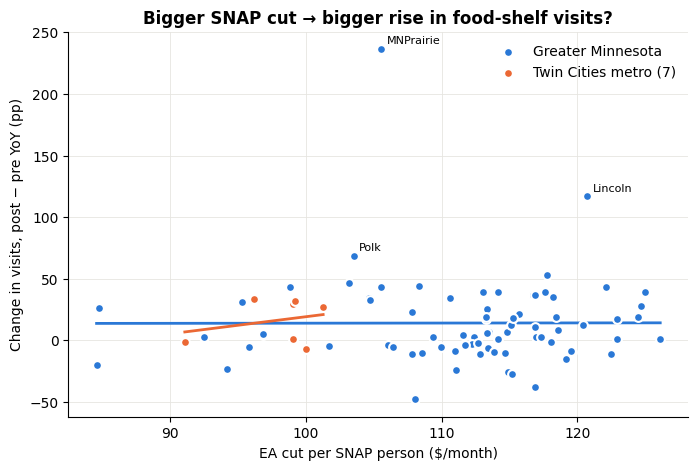

,dose,pre_yoy,post_yoy,did,metro
snap_unit,,,,,
MNPrairie,105.536,0.476,2.839,2.363,0
Lincoln,120.750,-1.453,-0.286,1.168,0
Polk,103.508,0.086,0.769,0.683,0
Rock,117.770,-0.299,0.234,0.533,0
Pipestone,103.137,0.127,0.594,0.466,0
Wright,108.359,-0.074,0.369,0.443,0
Nobles,98.814,-0.195,0.241,0.435,0
Roseau,122.120,0.111,0.546,0.435,0
Kandiyohi,105.493,-0.192,0.238,0.429,0


In [23]:
d = ea_data["visits"]
fig, ax = plt.subplots(figsize=(8, 5))
for flag, color, label in [(0, C1, "Greater Minnesota"), (1, C2, "Twin Cities metro (7)")]:
    s = d[d["metro"] == flag]
    ax.scatter(s["dose"], s["did"] * 100, s=40, color=color, label=label,
               edgecolor="white", linewidth=1.5, zorder=3)
    if len(s) > 2:
        b = np.polyfit(s["dose"], s["did"] * 100, 1)
        xs = np.linspace(s["dose"].min(), s["dose"].max(), 50)
        ax.plot(xs, np.polyval(b, xs), color=color, lw=2)
for unit, r in d.nlargest(3, "did").iterrows():
    ax.annotate(unit, (r["dose"], r["did"] * 100), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("EA cut per SNAP person ($/month)")
ax.set_ylabel("Change in visits, post − pre YoY (pp)")
ax.set_title("Bigger SNAP cut → bigger rise in food-shelf visits?")
ax.legend(frameon=False)
plt.show()

d.sort_values("did", ascending=False)[["dose", "pre_yoy", "post_yoy", "did", "metro"]].round(3).head(10)

## Robustness checks
Re-run the main Q5a model with each alternative. The conclusion should not hinge on one choice.

In [24]:
checks = {"balanced panel (default)": panel, "all sites": panel_all}
rows = []
for name, p in checks.items():
    for y in ["ln_visits", "ln_pounds"]:
        m = fe_reg(p, y)
        rows.append({"version": name, "outcome": y,
                     "beta_persons": m.params["ln_snap_persons"], "beta_benefit_pp": m.params["ln_benefit_pp"],
                     "p_benefit_pp": m.pvalues["ln_benefit_pp"], "n": int(m.nobs)})
pd.DataFrame(rows).round(3)
# Also try: ERROR_POLICY="null_both", TRIBE_POLICY="drop", MIN_REPORT_SHARE=0.8 (edit Analysis Settings and re-run all)

,version,outcome,beta_persons,beta_benefit_pp,p_benefit_pp,n
0,balanced panel (default),ln_visits,0.174,0.385,0.044,4559
1,balanced panel (default),ln_pounds,-0.044,0.291,0.163,4558
2,all sites,ln_visits,0.257,-0.027,0.903,4561
3,all sites,ln_pounds,0.000,-0.025,0.910,4560


## Findings (fill in after running)
| Sub-question | Answer | Evidence |
|---|---|---|
| Q5-A. Together or substitute? | _e.g. "Enrollment moves **with** food-shelf use (shared need), but more SNAP $/person **reduces** it."_ | Q5-A panel regression (β₁, β₂) |
| Q5-B. When benefits change? | _e.g. "After EA ended (Apr 2023 in accounting months), visits rose X% YoY; counties that lost $10 more per person saw Y pp more."_ | Q5-B dose coef + event chart |
| Q5-C. Differs by location? | _metro vs Greater MN; which counties responded most_ | Q5-C interaction + scatter |

**Caveats to state on the slide:** accounting-month timing; SNAP and food-shelf geographies differ (consortia, Tribal Nations); pounds partly reflect supply, not just demand; individuals are self-reported.